In [1]:
from bs4 import BeautifulSoup
import requests
import pandas as pd
import re
from datetime import datetime
from pymongo import MongoClient
import plotly.express as px
import dash
from dash import dcc, html, Input, Output


/opt/anaconda3/lib/python3.13/site-packages/dash/dash.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, parse_version


In [2]:
client = MongoClient('localhost', 27017)
db = client['olympics_db']
wins_collection = db['olympic-wins']

# read the excel file into a dataframe
wins_df = pd.read_excel('olympic-wins.xlsx')
wins_df['Country'] = wins_df['Country'].str.strip()   
print(wins_df.shape)
wins_df.head()


(1782, 8)


,Olympic_id,Year,Season,Country,Gold,Silver,Bronze,Total
0,O1,1896,Summer,United States,11,7,2,20
1,O1,1896,Summer,Greece,10,18,19,47
2,O1,1896,Summer,Germany,6,5,2,13
3,O1,1896,Summer,France,5,4,2,11
4,O1,1896,Summer,Great Britain,2,3,2,7


In [3]:
wins_collection.delete_many({})
wins_collection.insert_many(wins_df.to_dict('records'))
print('Documents in olympic-wins collection:', wins_collection.count_documents({}))


Documents in olympic-wins collection: 1782


## Step 2: Web Scrape Host Cities Table into MongoDB 
Scrape the host-cities table from
https://en.wikipedia.org/wiki/List_of_Olympic_Games_host_cities
and load it into a MongoDB collection named `olympic_cities`.

In [4]:
url = 'https://en.wikipedia.org/wiki/List_of_Olympic_Games_host_cities'
headers = {'User-Agent': 'Mozilla/5.0 (compatible; DATA320-StudentAssignment/1.0)'}
response = requests.get(url, headers=headers)

soup = BeautifulSoup(response.text, 'html.parser')
table = soup.find('table', class_='wikitable')
for br_tag in table.find_all('br'):
    br_tag.replace_with(', ')

all_rows = table.find_all('tr')
print('number of rows found:', len(all_rows))
print(all_rows[0])   # quick look at the header row

number of rows found: 65
<tr>
<th colspan="2" scope="colgroup">City
</th>
<th scope="col">Country
</th>
<th scope="col">Year
</th>
<th scope="col">Region
</th>
<th scope="col">Summer
</th>
<th scope="col">Winter
</th>
<th class="unsortable" scope="col">Opening ceremony
</th>
<th class="unsortable" scope="col">Closing ceremony
</th>
<th class="unsortable" scope="col"><abbr title="Reference(s)">Ref.</abbr>
</th></tr>


In [5]:
header_cells = all_rows[0].find_all(['th', 'td'])
expanded_headers = []
for cell in header_cells:
    colspan_val = int(cell.get('colspan', 1))
    label = cell.get_text().strip()
    for i in range(colspan_val):
        expanded_headers.append(label)
print('expanded headers:', expanded_headers)

num_cols = len(expanded_headers)
row_span_elements = [''] * num_cols
span_numbers = [0] * num_cols

data = []
for row in all_rows[1:]:
    row_col = 0
    row_data = []
    for td in row.find_all(['td', 'th']):
        if span_numbers[row_col] > 0:
            while(row_span_elements[row_col] != ''):
                row_data.append(row_span_elements[row_col])
                span_numbers[row_col] = span_numbers[row_col] - 1
                if span_numbers[row_col] == 0:
                    row_span_elements[row_col] = ''
                row_col = row_col + 1
            # after adding all span elements, process current <td> element
            if 'rowspan' in td.attrs:
                rowspan_val = int(td.get('rowspan', 1))
                colspan_val = int(td.get('colspan', 1))
                if rowspan_val > 1:
                    for i in range(colspan_val):
                        row_span_elements[row_col] = td.text.strip()
                        span_numbers[row_col] = rowspan_val - 1
                        row_data.append(td.text.strip())
                        row_col = row_col + 1
                else:
                    for i in range(colspan_val):
                        row_data.append(td.text.strip())
                        row_col = row_col + 1
            else:
                colspan_val = int(td.get('colspan', 1))
                for i in range(colspan_val):
                    row_data.append(td.text.strip())
                    row_col = row_col + 1
        else:
            if 'rowspan' in td.attrs:
                rowspan_val = int(td.get('rowspan', 1))
                colspan_val = int(td.get('colspan', 1))
                if rowspan_val > 1:
                    for i in range(colspan_val):
                        row_span_elements[row_col] = td.text.strip()
                        span_numbers[row_col] = rowspan_val - 1
                        row_data.append(td.text.strip())
                        row_col = row_col + 1
                else:
                    for i in range(colspan_val):
                        row_data.append(td.text.strip())
                        row_col = row_col + 1
            else:
                colspan_val = int(td.get('colspan', 1))
                for i in range(colspan_val):
                    row_data.append(td.text.strip())
                    row_col = row_col + 1
    if len(row_data) < num_cols:
        for i in range(len(row_data), num_cols):
            if span_numbers[i] > 0:
                row_data.append(row_span_elements[i])
                span_numbers[i] = span_numbers[i] - 1
    data.append(row_data)

df_raw = pd.DataFrame(data, columns=expanded_headers)
print(df_raw.shape)

city_col = []
for marker, name in zip(df_raw.iloc[:, 0], df_raw.iloc[:, 1]):
    if marker == '' or marker == name:
        city_col.append(name)
    else:
        city_col.append(marker + ' ' + name)

df_cities = df_raw.iloc[:, 2:].copy()      # everything after the two City columns
df_cities.insert(0, 'City', city_col)

print(df_cities.columns.tolist())
print(df_cities.shape)
df_cities.head(10)


expanded headers: ['City', 'City', 'Country', 'Year', 'Region', 'Summer', 'Winter', 'Opening ceremony', 'Closing ceremony', 'Ref.']
(64, 10)
['City', 'Country', 'Year', 'Region', 'Summer', 'Winter', 'Opening ceremony', 'Closing ceremony', 'Ref.']
(64, 9)


,City,Country,Year,Region,Summer,Winter,Opening ceremony,Closing ceremony,Ref.
0,Athens,Greece,1896,Europe,S005I,,6 April 1896,15 April 1896,
1,Paris,France,1900,Europe,S005II,,14 May 1900,28 October 1900,
2,St. Louis[a],United States,1904,North America,S005III,,1 July 1904,23 November 1904,
3,London[b],United Kingdom,1908,Europe,S005IV,,27 April 1908,31 October 1908,
4,Stockholm,Sweden,1912,Europe,S005V,,6 July 1912,22 July 1912,
5,† Berlin,Germany,1916,Europe,S006VI,,Cancelled due to WWI,Cancelled due to WWI,[11]
6,Antwerp[c],Belgium,1920,Europe,S007VII,,14 August 1920,12 September 1920,[12]
7,Chamonix,France,1924,Europe,,W001I,25 January 1924,5 February 1924,[13]
8,Paris,France,1924,Europe,S008VIII,,5 July 1924,27 July 1924,[14]
9,St. Moritz,Switzerland,1928,Europe,,W002II,11 February 1928,19 February 1928,[15]


In [6]:
# 1) introduce a Season column based on which of Summer/Winter has a value
df_cities['Season'] = df_cities.apply(lambda r: 'Summer' if r['Summer'] != '' else 'Winter', axis=1)

# 2) drop Summer, Winter, Ref
df_cities = df_cities.drop(columns=['Summer', 'Winter', 'Ref.'])

# 3) remove footnote references like [a], [12], [d] from these four columns
def remove_references(text):
    return re.sub(r'\[.*?\]', '', text).strip()

for col in ['City', 'Country', 'Opening ceremony', 'Closing ceremony']:
    df_cities[col] = df_cities[col].apply(remove_references)

# 4) introduce the olympic_id column O1, O2, O3, ...
df_cities['olympic_id'] = ['O' + str(i) for i in range(1, len(df_cities) + 1)]

print(df_cities.columns.tolist())
print(df_cities.shape)
df_cities.head(10)


['City', 'Country', 'Year', 'Region', 'Opening ceremony', 'Closing ceremony', 'Season', 'olympic_id']
(64, 8)


,City,Country,Year,Region,Opening ceremony,Closing ceremony,Season,olympic_id
0,Athens,Greece,1896,Europe,6 April 1896,15 April 1896,Summer,O1
1,Paris,France,1900,Europe,14 May 1900,28 October 1900,Summer,O2
2,St. Louis,United States,1904,North America,1 July 1904,23 November 1904,Summer,O3
3,London,United Kingdom,1908,Europe,27 April 1908,31 October 1908,Summer,O4
4,Stockholm,Sweden,1912,Europe,6 July 1912,22 July 1912,Summer,O5
5,† Berlin,Germany,1916,Europe,Cancelled due to WWI,Cancelled due to WWI,Summer,O6
6,Antwerp,Belgium,1920,Europe,14 August 1920,12 September 1920,Summer,O7
7,Chamonix,France,1924,Europe,25 January 1924,5 February 1924,Winter,O8
8,Paris,France,1924,Europe,5 July 1924,27 July 1924,Summer,O9
9,St. Moritz,Switzerland,1928,Europe,11 February 1928,19 February 1928,Winter,O10


In [7]:
cities_collection = db['olympic_cities']
cities_collection.delete_many({})
cities_collection.insert_many(df_cities.to_dict('records'))
print('Documents in olympic_cities collection:', cities_collection.count_documents({}))


Documents in olympic_cities collection: 64


### Q1: Five Summer Olympic Games with the lowest number of participating nations

  Olympic_id  Year  num_nations
0         O3  1904            8
1         O1  1896           11
2         O5  1912           19
3         O2  1900           19
4         O4  1908           19


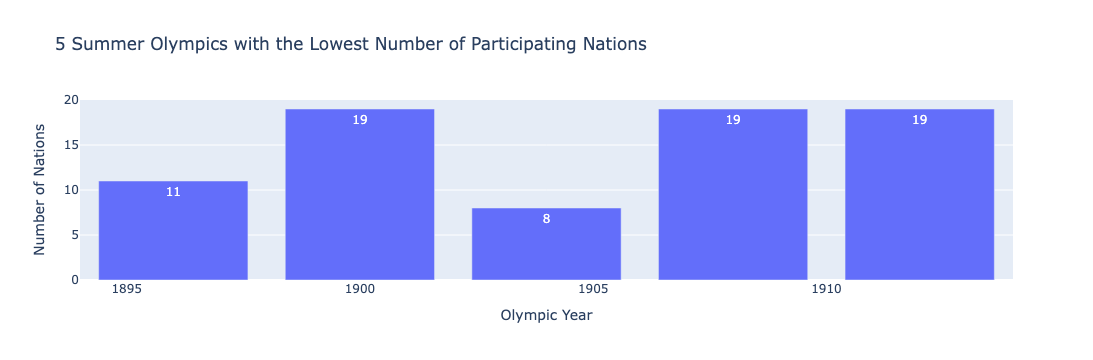

In [8]:
pipeline = [
    {'$match': {'Season': 'Summer'}},
    {'$group': {'_id': {'Olympic_id': '$Olympic_id', 'Year': '$Year'},
                'num_nations': {'$addToSet': '$Country'}}},
    {'$project': {'Olympic_id': '$_id.Olympic_id', 'Year': '$_id.Year',
                  'num_nations': {'$size': '$num_nations'}, '_id': 0}},
    {'$sort': {'num_nations': 1}},
    {'$limit': 5}
]
q1_results = list(wins_collection.aggregate(pipeline))
q1_df = pd.DataFrame(q1_results)
print(q1_df)

fig_q1 = px.bar(q1_df, x='Year', y='num_nations', text='num_nations',
                title='5 Summer Olympics with the Lowest Number of Participating Nations',
                labels={'num_nations': 'Number of Nations', 'Year': 'Olympic Year'})
fig_q1.show()


### Q2: Which Olympic Games were cancelled due to WWI or WWII?

In [9]:
cancelled_cursor = cities_collection.find(
    {'Opening ceremony': {'$regex': 'Cancelled'}},
    {'_id': 0, 'Year': 1, 'City': 1, 'Season': 1, 'Opening ceremony': 1}
)
cancelled_df = pd.DataFrame(list(cancelled_cursor))
print(cancelled_df)
print('Cancelled years:', cancelled_df['Year'].tolist())


                                City  Year       Opening ceremony  Season
0                           † Berlin  1916   Cancelled due to WWI  Summer
1  † Sapporo, Garmisch-Partenkirchen  1940  Cancelled due to WWII  Winter
2                  † Tokyo, Helsinki  1940  Cancelled due to WWII  Summer
3                † Cortina d'Ampezzo  1944  Cancelled due to WWII  Winter
4                           † London  1944  Cancelled due to WWII  Summer
Cancelled years: ['1916', '1940', '1940', '1944', '1944']


### Q3: Five countries with the highest overall medal counts

         Country  total_medals
0  United States          2985
1   Soviet Union          1204
2        Germany          1077
3  Great Britain           961
4         France           911


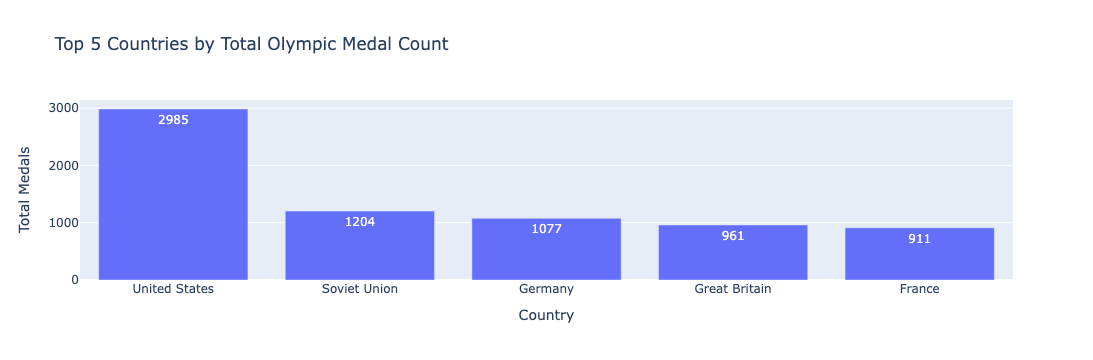

In [10]:
pipeline = [
    {'$group': {'_id': '$Country', 'total_medals': {'$sum': '$Total'}}},
    {'$sort': {'total_medals': -1}},
    {'$limit': 5}
]
q3_results = list(wins_collection.aggregate(pipeline))
q3_df = pd.DataFrame(q3_results).rename(columns={'_id': 'Country'})
print(q3_df)

fig_q3 = px.bar(q3_df, x='Country', y='total_medals', text='total_medals',
                title='Top 5 Countries by Total Olympic Medal Count',
                labels={'total_medals': 'Total Medals'})
fig_q3.show()


### Q4: Duration of each Olympic Games - five longest

  olympic_id       City  Year  Season  duration_days
3         O4     London  1908  Summer            187
1         O2      Paris  1900  Summer            167
2         O3  St. Louis  1904  Summer            145
5         O7    Antwerp  1920  Summer             29
7         O9      Paris  1924  Summer             22


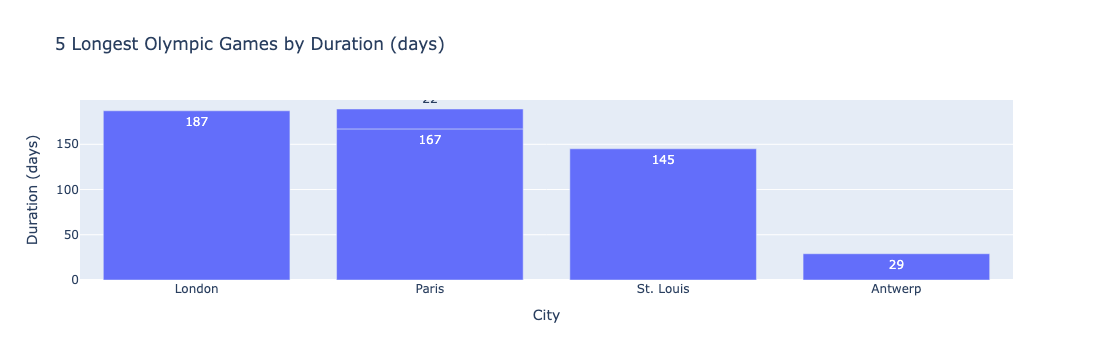

In [11]:
cities_docs = list(cities_collection.find({}, {'_id': 0}))
duration_rows = []
for doc in cities_docs:
    if 'Cancelled' in doc['Opening ceremony']:
        continue   # no real dates exist for cancelled Games

    # some editions list more than one date (e.g. 1956) separated by a comma -
    # just use the first date listed
    open_str = doc['Opening ceremony'].split(',')[0].strip()
    close_str = doc['Closing ceremony'].split(',')[0].strip()

    open_date = datetime.strptime(open_str, '%d %B %Y')
    close_date = datetime.strptime(close_str, '%d %B %Y')

    duration_rows.append({
        'olympic_id': doc['olympic_id'],
        'City': doc['City'],
        'Year': doc['Year'],
        'Season': doc['Season'],
        'duration_days': (close_date - open_date).days
    })

duration_df = pd.DataFrame(duration_rows).sort_values('duration_days', ascending=False)
top5_duration = duration_df.head(5)
print(top5_duration)

fig_q4 = px.bar(top5_duration, x='City', y='duration_days', text='duration_days',
                title='5 Longest Olympic Games by Duration (days)',
                labels={'duration_days': 'Duration (days)'})
fig_q4.show()


### Q5: Number of times specific cities have hosted the Olympics
Cities: London, Stockholm, Cortina d'Ampezzo, Melbourne, Berlin, Paris

                City  times_hosted
0              Paris             3
1             London             3
2          Stockholm             2
3  Cortina d'Ampezzo             2
4             Berlin             1
5          Melbourne             1


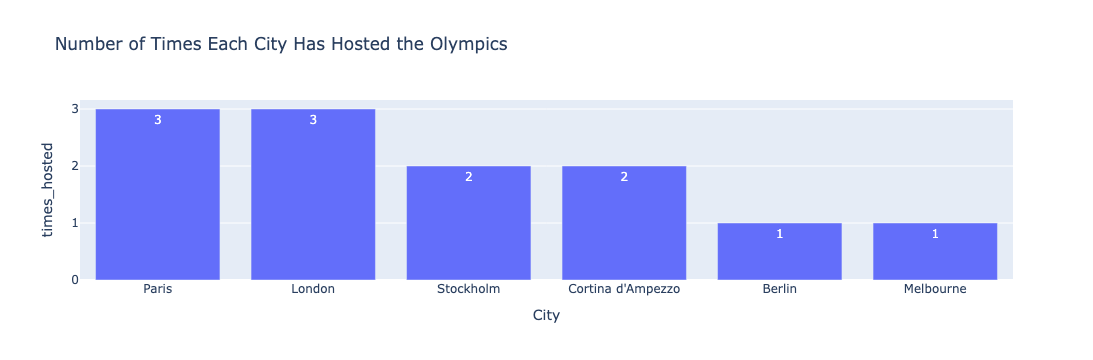

In [12]:
target_cities = ['London', 'Stockholm', "Cortina d'Ampezzo", 'Melbourne', 'Berlin', 'Paris']

cities_docs = list(cities_collection.find({}, {'_id': 0, 'City': 1}))
all_city_names = []
for doc in cities_docs:
    for name in doc['City'].split(', '):
        all_city_names.append(name)

city_series = pd.Series(all_city_names)
host_counts = city_series[city_series.isin(target_cities)].value_counts().reset_index()
host_counts.columns = ['City', 'times_hosted']
print(host_counts)

fig_q5 = px.bar(host_counts, x='City', y='times_hosted', text='times_hosted',
                title='Number of Times Each City Has Hosted the Olympics')
fig_q5.show()


### Q6: Countries earning fewer than five medals - each Summer Olympics

    count_under_5 Olympic_id  Year
0               3         O1  1896
1               6         O2  1900
2               5         O3  1904
3               7         O4  1908
4               4         O5  1912
5               9         O7  1920
6              15         O9  1924
7              16        O11  1928
8              11        O13  1932
9              12        O15  1936
10             18        O21  1948
11             23        O23  1952
12             18        O25  1956
13             26        O27  1960
14             21        O29  1964
15             22        O31  1968
16             26        O33  1972
17             19        O35  1976
18             18        O37  1980
19             26        O39  1984
20             28        O41  1988
21             36        O43  1992
22             43        O45  1996
23             38        O47  2000
24             29        O49  2004
25             43        O51  2008
26             46        O53  2012
27             43   

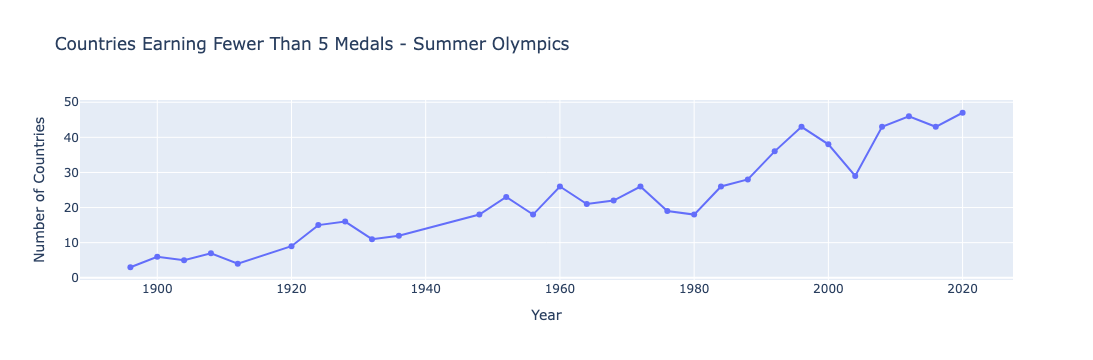

In [13]:
pipeline = [
    {'$match': {'Season': 'Summer', 'Total': {'$lt': 5}}},
    {'$group': {'_id': {'Olympic_id': '$Olympic_id', 'Year': '$Year'}, 'count_under_5': {'$sum': 1}}},
    {'$project': {'Olympic_id': '$_id.Olympic_id', 'Year': '$_id.Year', 'count_under_5': 1, '_id': 0}},
    {'$sort': {'Year': 1}}
]
q6_results = list(wins_collection.aggregate(pipeline))
q6_df = pd.DataFrame(q6_results)
print(q6_df)

fig_q6 = px.line(q6_df, x='Year', y='count_under_5', markers=True,
                 title='Countries Earning Fewer Than 5 Medals - Summer Olympics',
                 labels={'count_under_5': 'Number of Countries'})
fig_q6.show()


### Q7: Countries that participated in fewer than three Olympic Games
(presented as a table, no visualization required)

In [14]:
pipeline = [
    {'$group': {'_id': '$Country', 'num_editions': {'$addToSet': '$Olympic_id'}}},
    {'$project': {'num_editions': {'$size': '$num_editions'}}},
    {'$match': {'num_editions': {'$lt': 3}}},
    {'$sort': {'num_editions': 1, '_id': 1}}
]
q7_results = list(wins_collection.aggregate(pipeline))
q7_df = pd.DataFrame(q7_results).rename(columns={'_id': 'Country'})
print(q7_df)


                         Country  num_editions
0                       Barbados             1
1                   Burkina Faso             1
2                         Cyprus             1
3                       Djibouti             1
4                        Eritrea             1
5                          Gabon             1
6                      Guatemala             1
7                         Guyana             1
8                           Iraq             1
9                      Mauritius             1
10                    Mixed team             1
11                        Monaco             1
12                    Montenegro             1
13          Netherlands Antilles             1
14                      Paraguay             1
15                         Samoa             1
16                    San Marino             1
17                       Senegal             1
18                         Sudan             1
19                          Togo             1
20           

### Q8: Total gold/silver/bronze medals awarded each Olympic year

    Year  Gold  Silver  Bronze
0   1896    43      43      36
1   1900    96      94      94
2   1904    97      92      91
3   1908   110     107     107
4   1912   106     107     104
5   1920   158     152     139
6   1924   146     148     148
7   1928   133     130     134
8   1932   139     139     134
9   1936   158     157     158
10  1948   168     170     173
11  1952   171     174     181
12  1956   172     170     181
13  1960   180     175     187
14  1964   197     206     205
15  1968   209     209     215
16  1972   231     229     245
17  1976   235     236     253
18  1980   242     243     261
19  1984   265     258     282
20  1988   287     280     310
21  1992   317     315     354
22  1994    61      61      61
23  1996   271     273     298
24  1998    69      68      68
25  2000   300     300     327
26  2002    80      76      78
27  2004   301     300     325
28  2006    84      84      84
29  2008   302     303     353
30  2010    86      87      85
31  2012

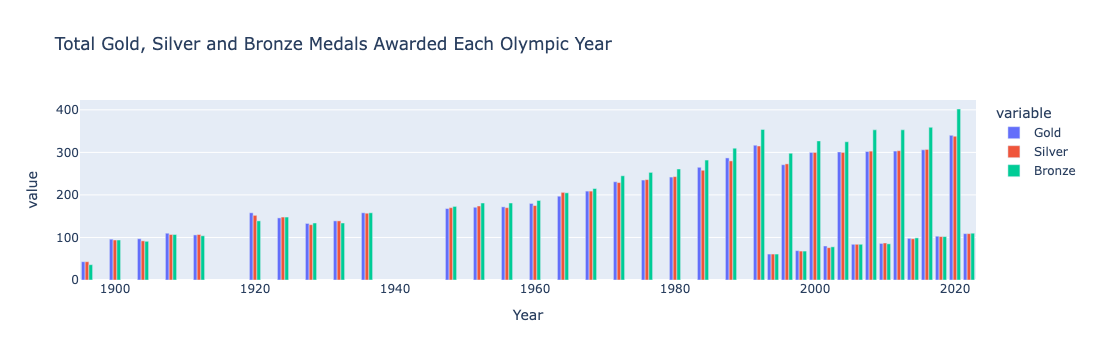

In [15]:
pipeline = [
    {'$group': {'_id': '$Year', 'Gold': {'$sum': '$Gold'}, 'Silver': {'$sum': '$Silver'}, 'Bronze': {'$sum': '$Bronze'}}},
    {'$sort': {'_id': 1}}
]
q8_results = list(wins_collection.aggregate(pipeline))
q8_df = pd.DataFrame(q8_results).rename(columns={'_id': 'Year'})
print(q8_df)

fig_q8 = px.bar(q8_df, x='Year', y=['Gold', 'Silver', 'Bronze'], barmode='group',
                title='Total Gold, Silver and Bronze Medals Awarded Each Olympic Year')
fig_q8.show()


### Bonus Q9: 1900 Olympics - countries with more silver medals than gold medals

In [16]:
pipeline = [
    {'$match': {'Year': 1900, '$expr': {'$gt': ['$Silver', '$Gold']}}},
    {'$project': {'_id': 0, 'Country': 1, 'Gold': 1, 'Silver': 1, 'Bronze': 1, 'Total': 1}}
]
q9_results = list(wins_collection.aggregate(pipeline))
q9_df = pd.DataFrame(q9_results)
print(q9_df)


       Country  Gold  Silver  Bronze  Total
0       France    31      41      40    112
1      Denmark     1       3       2      6
2   Mixed Team     1       2       3      6
3  Netherlands     1       2       3      6
4      Hungary     1       2       2      5
5      Austria     0       3       3      6
6       Norway     0       2       3      5
7        India     0       2       0      2
8      Bohemia     0       1       1      2


### Q10: Number of distinct cities that hosted the Olympics, per region

In [17]:
cities_docs = list(cities_collection.find({}, {'_id': 0, 'City': 1, 'Region': 1}))
region_rows = []
for doc in cities_docs:
    city_list = doc['City'].split(', ')
    region_list = doc['Region'].split(', ')
    for city_name, region_name in zip(city_list, region_list):
        region_rows.append({'City': city_name, 'Region': region_name})

region_df = pd.DataFrame(region_rows)
city_count_by_region = region_df.groupby('Region')['City'].nunique().reset_index(name='num_distinct_cities')
city_count_by_region = city_count_by_region.sort_values('num_distinct_cities', ascending=False)
print(city_count_by_region)


          Region  num_distinct_cities
1         Europe                   29
2  North America                   11
0           Asia                    9
3        Oceania                    3
4  South America                    1


## Step 4: Interactive Plotly Dash Dashboard (10 points)
A dropdown lets the user pick between four of the questions above
(Q1, Q3, Q5, Q8) and shows the matching graph.

In [18]:
app = dash.Dash(__name__)

app.layout = html.Div([
    html.H1('Olympic Games Analysis Dashboard', style={'textAlign': 'center'}),
    html.Div([
        html.Label('Choose a question to display:'),
        dcc.Dropdown(
            id='question-dropdown',
            options=[
                {'label': 'Q3: Top 5 countries by total medal count', 'value': 'q3'},
                {'label': 'Q4: 5 longest Olympic Games by duration', 'value': 'q4'},
                {'label': 'Q5: Number of times selected cities hosted the Olympics', 'value': 'q5'},
                {'label': 'Q6: Countries earning fewer than 5 medals - Summer Olympics', 'value': 'q6'},
            ],
            value='q3'
        )
    ], style={'width': '60%', 'margin': '0 auto'}),
    dcc.Graph(id='question-graph')
])

@app.callback(
    Output('question-graph', 'figure'),
    Input('question-dropdown', 'value')
)
def update_graph(selected_question):
    if selected_question == 'q3':
        return fig_q3
    elif selected_question == 'q4':
        return fig_q4
    elif selected_question == 'q5':
        return fig_q5
    elif selected_question == 'q6':
        return fig_q6

In [ ]:
if __name__ == '__main__':
    app.run(debug=True, use_reloader=False)

Dash is running on http://127.0.0.1:8050/

 * Serving Flask app '__main__'
 * Debug mode: on
